**The program for simulation of three-photon Rydberg excitation of 37P_{3/2} state in the external DC electric field. Supplemental material for the paper S.A.Spirin et al. Three-dimensional three-photon Stark spectroscopy of single Rydberg Rb atoms in an ultrahigh-vacuum glass cell with eight electrodes**

In [1]:
import numpy as np
import qutip as qt
from scipy.sparse.linalg import expm_multiply

def basis5(i):
    """
    Returns |i> for i=0..4 in a 5-level Hilbert space.
    Convention:
        0 -> |1>
        1 -> |2>
        2 -> |3>
        3 -> |4>
        4 -> |5>
    """
    return qt.basis(5, i)


def projector(i):
    """
    Returns |i><i| for i=0..4.
    """
    ket = basis5(i)
    return ket * ket.dag()


def transition(i, j):
    """
    Returns |i><j|.
    """
    return basis5(i) * basis5(j).dag()


def linewidth_dephasing_op(i, j, gamma_phi):
    """
    Collapse operator giving dephasing of coherence rho_ij
    at rate gamma_phi:
        L = sqrt(gamma_phi / 2) * (|i><i| - |j><j|)
    """
    return np.sqrt(gamma_phi / 2.0) * (projector(i) - projector(j))


# ============================================================
# Hamiltonian
# ============================================================

def five_level_hamiltonian(Omega12, Omega23, Omega34, Omega35,
                           Delta12, Delta23, Delta34, Delta35):
    """
    5-level system:

        |1> <-> |2> with Omega12, Delta12
        |2> <-> |3> with Omega23, Delta23
        |3> <-> |4> with Omega34, Delta34
        |3> <-> |5> with Omega35, Delta35

    Basis:
        0 -> |1>
        1 -> |2>
        2 -> |3>
        3 -> |4>
        4 -> |5>

    All parameters should be in consistent angular-frequency units.
    """

    P2 = projector(1)
    P3 = projector(2)
    P4 = projector(3)
    P5 = projector(4)

    s12 = transition(0, 1)
    s21 = transition(1, 0)

    s23 = transition(1, 2)
    s32 = transition(2, 1)

    s34 = transition(2, 3)
    s43 = transition(3, 2)

    s35 = transition(2, 4)
    s53 = transition(4, 2)

    H_detuning = (
        -Delta12 * P2
        -Delta23 * P3
        -Delta34 * P4
        -Delta35 * P5
    )

    H_coupling = (
        0.5 * Omega12 * (s12 + s21)
        + 0.5 * Omega23 * (s23 + s32)
        + 0.5 * Omega34 * (s34 + s43)
        + 0.5 * Omega35 * (s35 + s53)
    )

    return H_detuning + H_coupling


# ============================================================
# Collapse operators
# ============================================================

def collapse_operators(gamma21, gamma32, gamma43, gamma53,
                       laser_lw12=0.0, laser_lw23=0.0,
                       laser_lw34=0.0, laser_lw35=0.0):
    """
    Spontaneous decay:
        gamma21: |2> -> |1>
        gamma32: |3> -> |2>
        gamma43: |4> -> |3>
        gamma53: |5> -> |3>

    Laser linewidth / dephasing:
        laser_lw12 dephases |1><2|
        laser_lw23 dephases |2><3|
        laser_lw34 dephases |3><4|
        laser_lw35 dephases |3><5|
    """
    c_ops = []

    # Spontaneous decay
    if gamma21 > 0:
        c_ops.append(np.sqrt(gamma21) * transition(0, 1))  # |1><2|

    if gamma32 > 0:
        c_ops.append(np.sqrt(gamma32) * transition(1, 2))  # |2><3|

    if gamma43 > 0:
        c_ops.append(np.sqrt(gamma43) * transition(2, 3))  # |3><4|

    if gamma53 > 0:
        c_ops.append(np.sqrt(gamma53) * transition(2, 4))  # |3><5|

    # Laser linewidth as pure dephasing
    if laser_lw12 > 0:
        c_ops.append(linewidth_dephasing_op(0, 1, laser_lw12))

    if laser_lw23 > 0:
        c_ops.append(linewidth_dephasing_op(1, 2, laser_lw23))

    if laser_lw34 > 0:
        c_ops.append(linewidth_dephasing_op(2, 3, laser_lw34))

    if laser_lw35 > 0:
        c_ops.append(linewidth_dephasing_op(2, 4, laser_lw35))

    return c_ops



def qobj_to_csr(qobj):
    """
    Convert a QuTiP Qobj to a SciPy CSR sparse matrix
    for both QuTiP 4 and QuTiP 5 style backends.
    """
    data = qobj.data
    if hasattr(data, "as_scipy"):   # QuTiP 5
        return data.as_scipy().tocsr()
    return data.tocsr()             # QuTiP 4


def simultaneous_upper_detuning_spectrum_fast(
    scan_values,
    Delta34_start,
    Delta35_start,
    Omega12=0.0, Omega23=0.0, Omega34=0.0, Omega35=0.0,
    Delta12=0.0, Delta23=0.0,
    gamma21=0.0, gamma32=0.0, gamma43=0.0, gamma53=0.0,
    laser_lw12=0.0, laser_lw23=0.0, laser_lw34=0.0, laser_lw35=0.0,
    t_final=1.0
):
    """
    High-performance excitation spectrum for simultaneous scan of Delta34 and Delta35.

    For each scan value s:
        Delta34 = Delta34_start + s
        Delta35 = Delta35_start + s

    Uses direct Liouvillian propagation:
        rho(t) = exp(L t) rho(0)

    No unnecessary time grid is used.

    Returns
    -------
    Delta34_vals : np.ndarray
    Delta35_vals : np.ndarray
    P4_vals      : np.ndarray
    P5_vals      : np.ndarray
    P_upper_vals : np.ndarray
    """

    scan_values = np.asarray(scan_values, dtype=float)

    # --------------------------------------------------------
    # Initial state |1><1|
    # --------------------------------------------------------
    rho0 = projector(0)
    rho0_vec = qt.operator_to_vector(rho0).full().ravel()

    # --------------------------------------------------------
    # Collapse operators (constant for all scan points)
    # --------------------------------------------------------
    c_ops = collapse_operators(
        gamma21, gamma32, gamma43, gamma53,
        laser_lw12, laser_lw23, laser_lw34, laser_lw35
    )

    # --------------------------------------------------------
    # Build Hamiltonian in a split form:
    #
    # H = H_base + Delta34 * (-|4><4|) + Delta35 * (-|5><5|)
    #
    # where H_base already contains:
    #   Delta12, Delta23, couplings, and the common lower detuning structure
    #   but with Delta34 = Delta35 = 0
    # --------------------------------------------------------
    H_base = five_level_hamiltonian(
        Omega12, Omega23, Omega34, Omega35,
        Delta12, Delta23, 0.0, 0.0
    )

    P4 = projector(3)   # |4><4|
    P5 = projector(4)   # |5><5|

    # Liouvillian pieces
    L_base = qt.liouvillian(H_base, c_ops)
    L_d34 = qt.liouvillian(-P4, [])
    L_d35 = qt.liouvillian(-P5, [])

    # Since both detunings are scanned with the same scan variable s:
    #
    # Delta34 = Delta34_start + s
    # Delta35 = Delta35_start + s
    #
    # then:
    #
    # L(s) = L_offset + s * L_scan
    # --------------------------------------------------------
    L_offset = L_base + Delta34_start * L_d34 + Delta35_start * L_d35
    L_scan = L_d34 + L_d35

    L_offset_csr = qobj_to_csr(L_offset)
    L_scan_csr = qobj_to_csr(L_scan)

    # --------------------------------------------------------
    # Diagonal population indices in vectorized density matrix
    # QuTiP vectorization is column-stacking.
    # For N=5, diagonal rho_ii is at index i*(N+1)
    # --------------------------------------------------------
    N = 5
    idx_p4 = 3 * (N + 1)   # rho_44
    idx_p5 = 4 * (N + 1)   # rho_55

    Delta34_vals = Delta34_start + scan_values
    Delta35_vals = Delta35_start + scan_values

    P4_vals = np.empty(len(scan_values), dtype=float)
    P5_vals = np.empty(len(scan_values), dtype=float)
    P_upper_vals = np.empty(len(scan_values), dtype=float)

    # --------------------------------------------------------
    # Main scan loop
    # --------------------------------------------------------
    for k, s in enumerate(scan_values):
        L_current = L_offset_csr + s * L_scan_csr

        # Propagate only to final time, no intermediate time steps
        rho_t_vec = expm_multiply(L_current * t_final, rho0_vec)
        rho_t_vec = np.asarray(rho_t_vec).ravel()

        p4 = np.real(rho_t_vec[idx_p4])
        p5 = np.real(rho_t_vec[idx_p5])

        # Small numerical cleanup
        if p4 < 0 and abs(p4) < 1e-14:
            p4 = 0.0
        if p5 < 0 and abs(p5) < 1e-14:
            p5 = 0.0

        P4_vals[k] = p4
        P5_vals[k] = p5
        P_upper_vals[k] = p4 + p5

    return Delta34_vals, Delta35_vals, P4_vals, P5_vals, P_upper_vals

In [3]:
def save_simultaneous_spectrum_csv(
    filename,
    scan_values,
    Delta34_vals,
    Delta35_vals,
    P4_vals,
    P5_vals,
    P_upper_vals,
    freq_unit_scale=2.0 * np.pi
):
    """
    Save simultaneous scan spectrum data to CSV.

    Parameters
    ----------
    filename : str
        Output CSV filename.
    scan_values : array
        Common scan variable in angular frequency units.
    Delta34_vals : array
        Scanned Delta34 values in angular frequency units.
    Delta35_vals : array
        Scanned Delta35 values in angular frequency units.
    P4_vals, P5_vals, P_upper_vals : array
        Excitation probabilities.
    freq_unit_scale : float
        Scale factor for converting angular frequency to plotted units.
        Default: 2*pi*1e6, so output detunings are in MHz.
    """

    data = np.column_stack([
        scan_values / freq_unit_scale,
        Delta34_vals / freq_unit_scale,
        Delta35_vals / freq_unit_scale,
        P4_vals,
        P5_vals,
        P_upper_vals
    ])

    header = (
        "scan_variable_MHz,"
        "Delta34_MHz,"
        "Delta35_MHz,"
        "P4,"
        "P5,"
        "P4_plus_P5"
    )

    np.savetxt(
        filename,
        data,
        delimiter=",",
        header=header,
        comments=""
    )


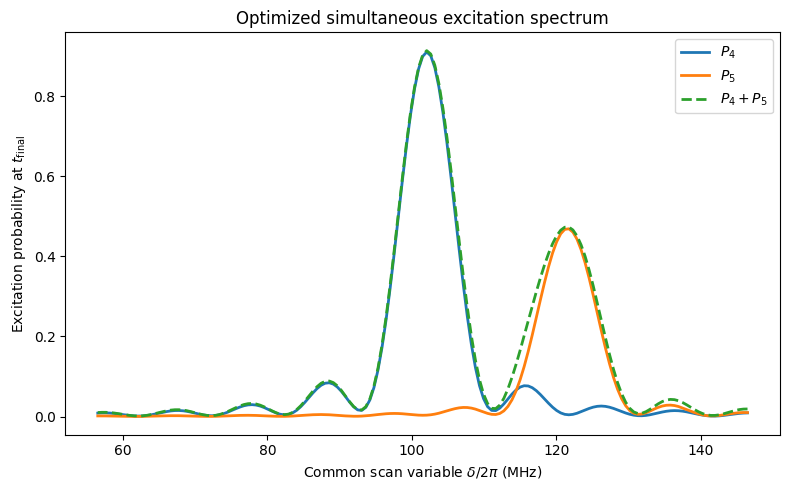

In [4]:
if __name__ == "__main__":
    import matplotlib.pyplot as plt

    MHz = 2.0 * np.pi 
    # Fixed interaction time
    t_final = 0.1
    # Rabi frequencies
    Omega12 = 100.0 * MHz
    Omega23 = 2000.0 * MHz
    Omega34 = 86.0 * MHz
    Omega35 = 50.0 * MHz

    # Lower detunings
    Delta12 = 10.0 * MHz
    Delta23 = -200.0 * MHz

   
    Ex=0
    Ey=2.5
    Ez=0
    alpha32=16.24
    alpha12=19.4
    # Upper detuning starting values
    Delta34_start = alpha32*(Ey**2+Ex**2+Ez**2)* MHz
    Delta35_start = alpha12*(Ey**2+Ex**2+Ez**2)* MHz

    # Decay rates
    tau2 = 26e-3
    tau3 = 46e-3
    tau4 = 43
    tau5 = 43

    gamma21 = 1.0 / tau2
    gamma32 = 1.0 / tau3
    gamma43 = 1.0 / tau4
    gamma53 = 1.0 / tau5

    # Laser linewidths
    laser_lw12 = 0.3 * MHz
    laser_lw23 = 0.3 * MHz
    laser_lw34 = 0.3 * MHz
    laser_lw35 = 0.3 * MHz

  

    # Common simultaneous scan
    scan_values = np.linspace(-45* MHz-Delta34_start,45*MHz- Delta34_start, 161)

    Delta34_vals, Delta35_vals, P4_vals, P5_vals, P_upper_vals = \
        simultaneous_upper_detuning_spectrum_fast(
            scan_values=scan_values,
            Delta34_start=Delta34_start,
            Delta35_start=Delta35_start,
            Omega12=Omega12,
            Omega23=Omega23,
            Omega34=Omega34,
            Omega35=Omega35,
            Delta12=Delta12,
            Delta23=Delta23,
            gamma21=gamma21,
            gamma32=gamma32,
            gamma43=gamma43,
            gamma53=gamma53,
            laser_lw12=laser_lw12,
            laser_lw23=laser_lw23,
            laser_lw34=laser_lw34,
            laser_lw35=laser_lw35,
            t_final=t_final
        )

    plt.figure(figsize=(8, 5))
    plt.plot(-scan_values / MHz, P4_vals, label=r"$P_4$", lw=2)
    plt.plot(-scan_values / MHz, P5_vals, label=r"$P_5$", lw=2)
    plt.plot(-scan_values / MHz, P_upper_vals, "--", label=r"$P_4 + P_5$", lw=2)
    plt.xlabel(r"Common scan variable $\delta / 2\pi$ (MHz)")
    plt.ylabel(r"Excitation probability at $t_{\mathrm{final}}$")
    plt.title("Optimized simultaneous excitation spectrum")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [18]:
save_simultaneous_spectrum_csv(
    filename="simultaneous_excitation_spectrum.csv",
    scan_values=scan_values,
    Delta34_vals=Delta34_vals,
    Delta35_vals=Delta35_vals,
    P4_vals=P4_vals,
    P5_vals=P5_vals,
    P_upper_vals=P_upper_vals)